Total Transactions Analyzed: 284,807
Actual Fraud Cases: 492 (0.173% fraud rate) | Total Fraud Volume: EUR 60,127.97

--- PATH 1: NORMAL THRESHOLD RULE (Amount > EUR 1,500) ---
Alerts Triggered: 1,334 | Fraud Caught (Recall): 0.6% | Precision: 0.2% | Fraud EUR Caught: EUR 5,440.48

--- PATH 2: UNSUPERVISED ISOLATION FOREST ML ---
Alerts Triggered: 570 | Fraud Caught (Recall): 31.7% | Precision: 27.4% | Fraud EUR Caught: EUR 15,105.46

Exported top 500 most anomalous transactions to Flagged_Suspicious_Transactions.csv


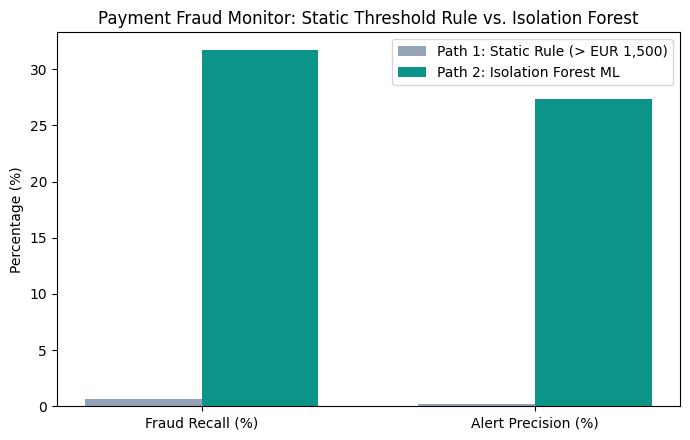

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import recall_score, precision_score

# 1. Load Transaction Log (284,807 European Cardholder Transactions)
txns = pd.read_csv('creditcard.csv')
total_txns = len(txns)
total_fraud = txns['Class'].sum()
total_fraud_eur = txns.loc[txns['Class'] == 1, 'Amount'].sum()

print(f"Total Transactions Analyzed: {total_txns:,}")
print(f"Actual Fraud Cases: {total_fraud:,} ({total_fraud / total_txns:.3%} fraud rate) | Total Fraud Volume: EUR {total_fraud_eur:,.2f}\n")

# ==========================================================
# PATH 1: NORMAL SQL / COMPLIANCE THRESHOLD RULE
# Rule: Flag any transaction exceeding EUR 1,500
# ==========================================================
rule_flag = (txns['Amount'] > 1500).astype(int)
rule_recall = recall_score(txns['Class'], rule_flag)
rule_prec = precision_score(txns['Class'], rule_flag)
rule_caught_eur = txns.loc[(rule_flag == 1) & (txns['Class'] == 1), 'Amount'].sum()

print("--- PATH 1: NORMAL THRESHOLD RULE (Amount > EUR 1,500) ---")
print(f"Alerts Triggered: {rule_flag.sum():,} | Fraud Caught (Recall): {rule_recall:.1%} | Precision: {rule_prec:.1%} | Fraud EUR Caught: EUR {rule_caught_eur:,.2f}\n")

# ==========================================================
# PATH 2: UNSUPERVISED MACHINE LEARNING (ISOLATION FOREST)
# Learns multi-dimensional behavioral anomalies across V1–V28 + Amount
# ==========================================================
X_features = txns.drop(columns=['Class', 'Time'])
iso = IsolationForest(n_estimators=150, contamination=0.002, random_state=42, n_jobs=-1)
ml_flag = (iso.fit_predict(X_features) == -1).astype(int)

# Compute anomaly score (lower = more anomalous) to rank top suspicious alerts
txns['Anomaly_Score'] = iso.decision_function(X_features).round(4)

ml_recall = recall_score(txns['Class'], ml_flag)
ml_prec = precision_score(txns['Class'], ml_flag)
ml_caught_eur = txns.loc[(ml_flag == 1) & (txns['Class'] == 1), 'Amount'].sum()

print("--- PATH 2: UNSUPERVISED ISOLATION FOREST ML ---")
print(f"Alerts Triggered: {ml_flag.sum():,} | Fraud Caught (Recall): {ml_recall:.1%} | Precision: {ml_prec:.1%} | Fraud EUR Caught: EUR {ml_caught_eur:,.2f}\n")

# 3. Export Top 500 Most Anomalous Transactions for Risk Operations Review
flagged_out = txns[ml_flag == 1].sort_values('Anomaly_Score', ascending=True)[['Time', 'Amount', 'Anomaly_Score', 'Class']].head(500)
flagged_out.to_csv('Flagged_Suspicious_Transactions.csv', index=False)
print(f"Exported top {len(flagged_out)} most anomalous transactions to Flagged_Suspicious_Transactions.csv")

# 4. Plot & Save Dual-Path Fraud Detection Comparison Chart
metrics = ['Fraud Recall (%)', 'Alert Precision (%)']
path1_vals = [rule_recall * 100, rule_prec * 100]
path2_vals = [ml_recall * 100, ml_prec * 100]

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width/2, path1_vals, width, label='Path 1: Static Rule (> EUR 1,500)', color='#94A3B8')
ax.bar(x + width/2, path2_vals, width, label='Path 2: Isolation Forest ML', color='#0D9488')
ax.set_ylabel('Percentage (%)')
ax.set_title('Payment Fraud Monitor: Static Threshold Rule vs. Isolation Forest')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
plt.tight_layout()
plt.savefig('fraud_detection_comparison.png', dpi=300)
plt.show()